## Time Series Decomposition, Stationarity & Baseline Forecasting
### AirPassengers Dataset
- **Course:** Statistics and Machine Learning
- **Format:** Individual task
- **Overview:** You will explore, decompose, and forecast ONE time series using simple baseline methods. Afterwards you will present your results to your (3-4) groupmates and compare them.

---

### Fairness note
Exercises 3-5 in this group project (Baseline Forecasting, Classical Forecasting, ML Forecasting) use:
- the **same dataset**
- the **same cleaning steps**
- the **same time-based train/test split** (last 24 months = test set)
- the **same number of required evaluation metrics** (3: MAE, RMSE, MAPE)

> This is intentional! It means when you compare results with your groupmates later, any differences you see come from the **forecasting approach itself**, not from different data handling.
> Important Note: Do not change the split or the cleaning steps described below, even if you think another approach would work better -> consistency across the group matters more here than optimizing your individual score.

> **Note on comparability:** Exercises 1-2 (clustering) and Exercises 3-5 (forecasting) solve fundamentally different kinds of problems and are **not** comparable on the same metrics -> see `GroupDebriefComparison.ipynb` for how the group should discuss this.

---


## 1. Dataset

**File:** [`airline-passengers.csv`](https://www.kaggle.com/datasets/rakannimer/air-passengers) (the classic AirPassengers dataset)

**Columns:**

| Column | Meaning |
|---|---|
| Month | Year-Month, e.g. `1949-01` |
| Passengers | Total monthly international airline passengers (in thousands) |

The dataset covers **January 1949 to December 1960** (144 monthly observations).

Place `airline-passengers.csv` in the same folder as this notebook before you start.


## 2. Data Preparation (required -> identical for Exercises 3-5)

Follow these steps **in order**. Do not skip or reorder any step.

1. **Load the dataset** with pandas and display `.shape`, `.head()`, `.info()`, and basic descriptive statistics (`.describe()`) of the `Passengers` column.
2. **Parse `Month`** as a proper datetime and set it as the DataFrame index. Set the frequency explicitly to monthly (`'MS'`).
3. **Check for missing values and gaps** in the monthly index (there should be none, but check and print what you found).
4. **Plot the raw series** (Passengers vs. time) to get a first visual impression -> do not skip this, you will need it to answer Section 7.
5. **Report** the mean, standard deviation, minimum, and maximum of `Passengers` over the full series.


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error, mean_absolute_error

df = pd.read_csv(r"C:\python\srh python\Statistics-and-Machine-Learning\Week-4\Lab-Assignments\airline-passengers.csv")
df.head()



,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [22]:
print("Shape:", df.shape)

print("\nHead:")
print(df.head())

print("\nInfo:")
df.info()

print("\nDescriptive statistics of Passengers:")
print(df['Passengers'].describe())


Shape: (144, 2)

Head:
     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121

Info:
<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Month       144 non-null    str  
 1   Passengers  144 non-null    int64
dtypes: int64(1), str(1)
memory usage: 2.4 KB

Descriptive statistics of Passengers:
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Passengers, dtype: float64


In [23]:
df['Month'] = pd.to_datetime(df['Month'])   
df = df.set_index('Month')                  
df = df.asfreq('MS')                 

print(df.index)    
print("\n", df.head())
print(df.isnull().sum())


DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01', '1949-04-01',
               '1949-05-01', '1949-06-01', '1949-07-01', '1949-08-01',
               '1949-09-01', '1949-10-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[us]', name='Month', length=144, freq='MS')

             Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
Passengers    0
dtype: int64


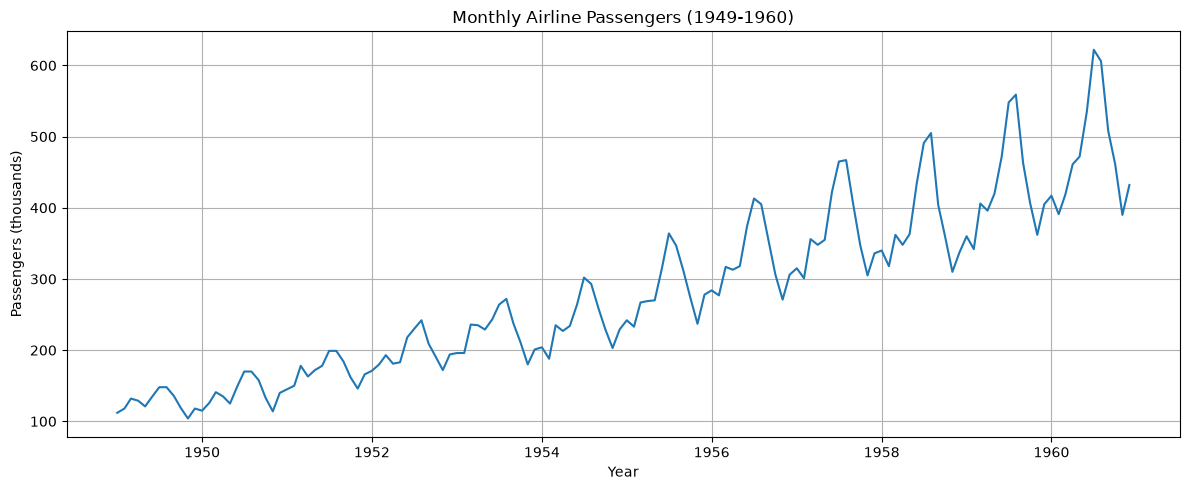

In [24]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Passengers'])
plt.title('Monthly Airline Passengers (1949-1960)')
plt.xlabel('Year')
plt.ylabel('Passengers (thousands)')
plt.grid(True)
plt.tight_layout()
plt.show()


In [25]:
print("Mean:", df['Passengers'].mean().round(2))
print("Std Dev:", df['Passengers'].std().round(2))
print("Minimum:", df['Passengers'].min())
print("Maximum:", df['Passengers'].max())


Mean: 280.3
Std Dev: 119.97
Minimum: 104
Maximum: 622


## 3. Time-Based Train/Test Split (required -> identical for Exercises 3-5)

- **Do not randomly shuffle** the data -> for time series we must respect the order of time.
- Use the **last 24 months** (the final 2 years, i.e. all of 1959-1960) as the **test set**. Everything before that is the **training set**.
- Print the date range and number of observations in both `train` and `test` to confirm the split.

**Do not change this split.** It must be identical across Exercises 3, 4, and 5 so your final comparison is fair.


In [ ]:
train = df.iloc[:-24]  
test = df.iloc[-24:]  

print("Train range:", train.index.min().date(), "to", train.index.max().date())
print("Train observations:", len(train))

print("\nTest range:", test.index.min().date(), "to", test.index.max().date())
print("Test observations:", len(test))


Train range: 1949-01-01 to 1958-12-01
Train observations: 120

Test range: 1959-01-01 to 1960-12-01
Test observations: 24


## 4. Libraries

```
pandas
numpy
matplotlib
seaborn
statsmodels.tsa.seasonal (seasonal_decompose)
statsmodels.tsa.stattools (adfuller)
sklearn.metrics (mean_absolute_error, mean_squared_error)
```

> **Note:** MAPE is not always available directly in `sklearn.metrics` depending on your version -> feel free to write a 2-3 line helper function `mape(y_true, y_pred)`.


## 5. Analysis & Baseline Models

1. **Decomposition:** apply `seasonal_decompose` (multiplicative model, `period=12`) to the **full** series and plot the resulting Trend, Seasonality, and Residual components.
2. **Stationarity check:** run the Augmented Dickey-Fuller (ADF) test on the raw series and report the p-value. Then apply first-order differencing (`.diff()`) and re-run the ADF test on the differenced series. Report both p-values and state whether each series is stationary at the 5% level.
3. **Baseline forecasts** (fit conceptually on train, evaluated on the 24-month test period):
   - **Naive forecast:** every test-period prediction = the last observed value in the training set.
   - **Seasonal naive forecast:** each test-period prediction = the value from the same month one year earlier (12 months before).
   - **Moving average forecast:** each test-period prediction = the average of the last 12 observed values in the training set (a flat-line forecast, recomputed only once from the training data).


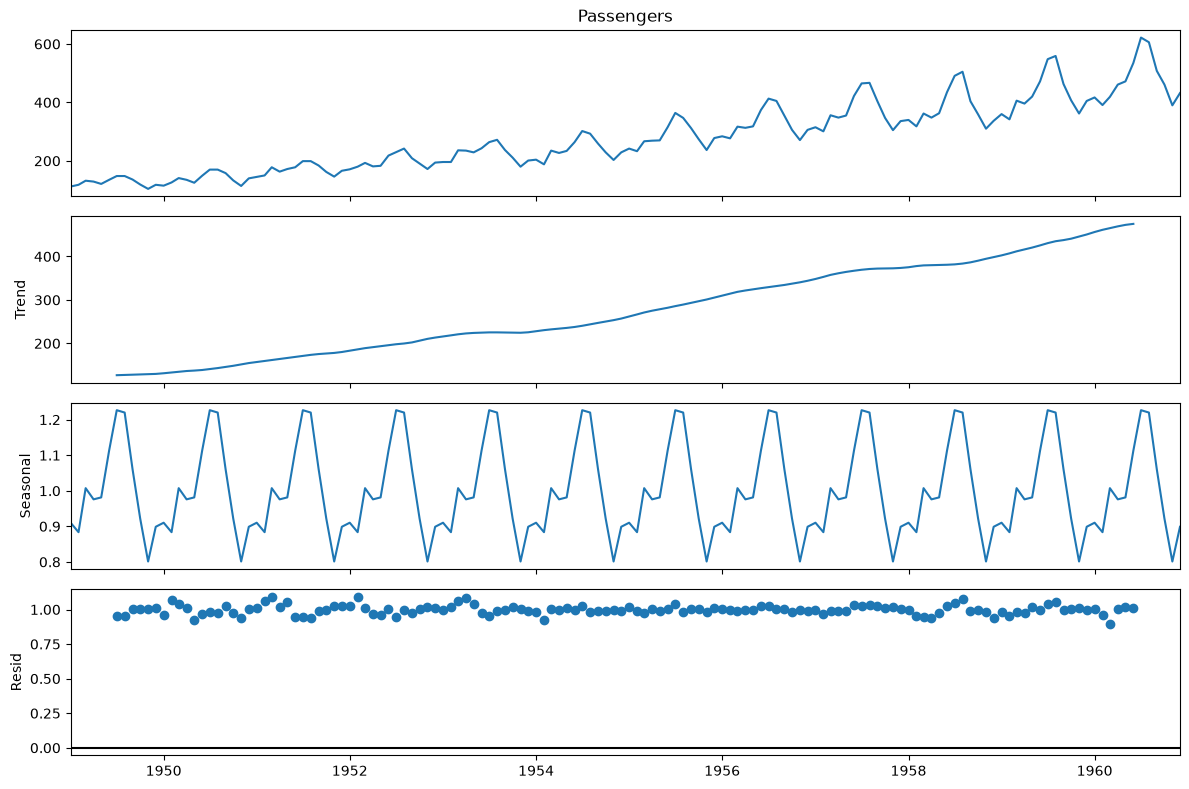

In [27]:
decomposition = seasonal_decompose(df['Passengers'], model='multiplicative', period=12)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()


In [ ]:
adf_raw = adfuller(df['Passengers'])
print("RAW SERIES")
print(f"ADF p-value: {adf_raw[1]:.4f}")
print("Stationary at 5%?", "Yes" if adf_raw[1] < 0.05 else "No")
 

diff_series = df['Passengers'].diff().dropna() 

adf_diff = adfuller(diff_series)
print("\nDIFFERENCED SERIES")
print(f"ADF p-value: {adf_diff[1]:.4f}")
print("Stationary at 5%?", "Yes" if adf_diff[1] < 0.05 else "No")


RAW SERIES
ADF p-value: 0.9919
Stationary at 5%? No

DIFFERENCED SERIES
ADF p-value: 0.0542
Stationary at 5%? No


In [29]:
naive_value = train['Passengers'].iloc[-1]
naive_forecast = pd.Series(naive_value, index=test.index)

seasonal_naive_forecast = df['Passengers'].shift(12).loc[test.index]


In [30]:
ma_value = train['Passengers'].iloc[-12:].mean()   # average of last 12 training values
ma_forecast = pd.Series(ma_value, index=test.index)


In [31]:
print("Naive:", round(naive_value, 1))
print("Moving Average:", round(ma_value, 1))
print("\nSeasonal Naive (first 3):")
print(seasonal_naive_forecast.head(3))


Naive: 337
Moving Average: 381.0

Seasonal Naive (first 3):
Month
1959-01-01    340.0
1959-02-01    318.0
1959-03-01    362.0
Freq: MS, Name: Passengers, dtype: float64


## 6. Evaluation & Visualization

**Required metrics** (compute for all 3 baselines, on the 24-month test set):
- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- MAPE (Mean Absolute Percentage Error)

Present these in a small comparison table (rows = Naive / Seasonal Naive / Moving Average, columns = the 3 metrics).

**Required visualizations** (3 total):
1. **Decomposition plot** -> the 4-panel output of `seasonal_decompose` (Observed, Trend, Seasonal, Residual).
2. **Original vs. differenced series plot** -> two line plots (or one figure, two subplots) showing the raw series and the first-differenced series, so the effect of differencing on stationarity is visible.
3. **Forecast comparison plot** -> one figure showing the training history, the actual test values, and all 3 baseline forecasts as separate lines over the test period.


In [32]:
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


In [33]:
y_true = test['Passengers']

forecasts = {
    'Naive': naive_forecast,
    'Seasonal Naive': seasonal_naive_forecast,
    'Moving Average': ma_forecast
}

results = []
for name, y_pred in forecasts.items():
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape_val = mape(y_true, y_pred)
    results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape_val})

results_df = pd.DataFrame(results).set_index('Model')
print(results_df.round(2))
results_df.round(2)


                   MAE    RMSE   MAPE
Model                                
Naive           115.25  137.33  23.58
Seasonal Naive   47.58   49.99  10.52
Moving Average   77.83  103.21  15.47


,MAE,RMSE,MAPE
Model,,,
Naive,115.25,137.33,23.58
Seasonal Naive,47.58,49.99,10.52
Moving Average,77.83,103.21,15.47


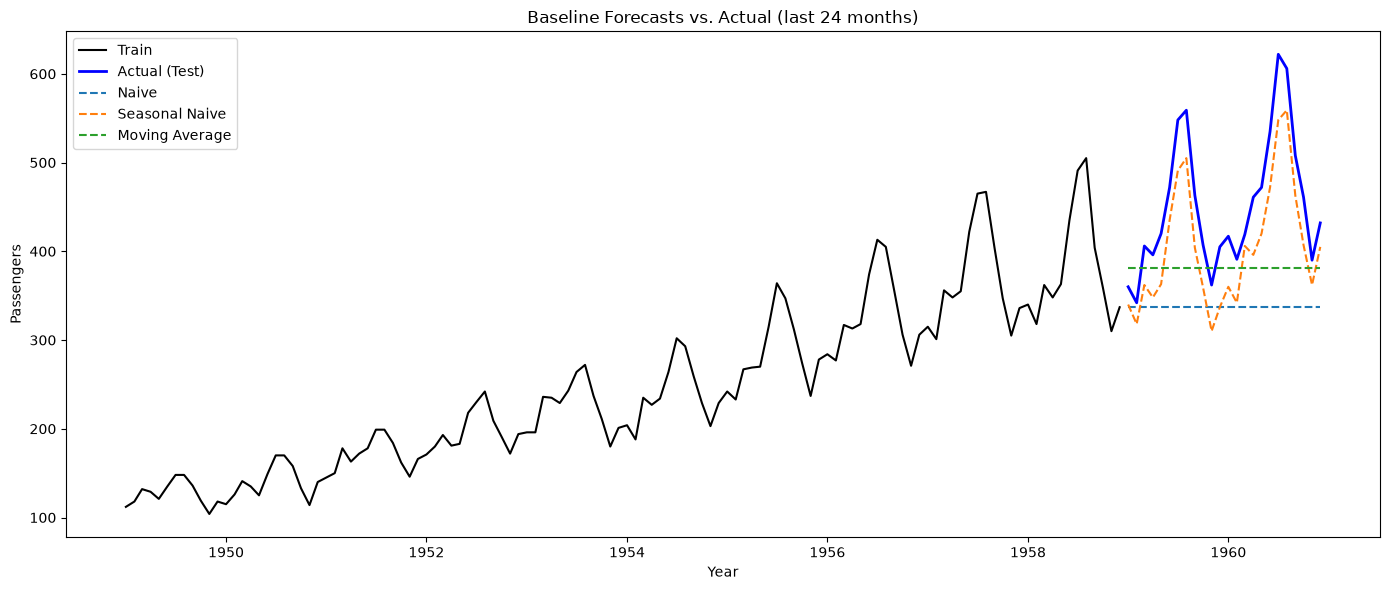

In [34]:
plt.figure(figsize=(14, 6))

# Training history
plt.plot(train.index, train['Passengers'], label='Train', color='black')

# Actual test values
plt.plot(test.index, test['Passengers'], label='Actual (Test)', color='blue', linewidth=2)

# The 3 baseline forecasts
plt.plot(test.index, naive_forecast, label='Naive', linestyle='--')
plt.plot(test.index, seasonal_naive_forecast, label='Seasonal Naive', linestyle='--')
plt.plot(test.index, ma_forecast, label='Moving Average', linestyle='--')

plt.title('Baseline Forecasts vs. Actual (last 24 months)')
plt.xlabel('Year')
plt.ylabel('Passengers')
plt.legend()
plt.tight_layout()
plt.show()


## 7. Reflection Questions (write short answers, 1-2 sentences each)

1. Looking at your decomposition plot, describe the trend and seasonality you see -> is the trend increasing, decreasing, or stable? How strong does the seasonal pattern look?
2. Was the raw series stationary according to the ADF test? Did differencing make it (more) stationary? How do you know?
3. Which of the 3 baseline methods performed best on the test set, and does that match your intuition from looking at the decomposition (e.g., a series with strong seasonality should favor the seasonal naive method)?
4. If you had to explain a "baseline forecast" to someone who has never studied ML, what is the one-sentence idea behind it, and why do we bother with something so simple before trying advanced models?
5. Look at the forecast comparison plot -> where do the baselines struggle most (e.g., peaks, troughs, the trend drifting away)? Any patterns?


1. Yes looking at the decompostion plot we can say that the trend is increase since the 1950-1960. The seasonal pattern has a flucuating pattern it peaks in summer and dips in winter.
2. The raw series is not stationary according to ADF test and differencing help the p-value drop well below 0.05 which made it stationary(differencing removed the trend).
3. The Seasonal Naive method perfomed best on the test set with lowest error across all three metrics, and Yes this matches my intutition from the decompostion plot, the series has a very strong repeating yearly seasonal pattern because seasonal naive predicts each month using the same month one year earlier, it captures that pattern while the Naive and Moving average methods are fllat line that ignore the seasonality so they did much worse.
4. A Baseline forecast is a simple common guess made using an easy rule like next month will be the same as last month this month will be like the same month last year without any complicated maths or ML.
5. The two flat bseline Naive and moving average struggle the most they are straight horizontal lines, so they completely miss the peaks and troughs sitting far below the actual summer peaks and above the winter dips. The clearest pattern is that all three baselines struggle with upward trend drifiting away because the series keeps growing the actual values in the second year climb even higher, and ven the Seasonal naive forecast falls short at the peaks since it copies the lower values from 1 year earlier. So the baselines struggle most at the yearly peaks, and the gap gets worse the further into the future we forecast.

## 8. Deliverables Checklist

Before the group debrief, make sure your notebook contains:

- [ ] Data loaded and cleaned (Section 2)
- [ ] Correct time-based train/test split (Section 3)
- [ ] Decomposition and stationarity analysis completed (Section 5)
- [ ] All 3 baseline models computed (Section 5)
- [ ] All 3 required metrics reported for all 3 baselines (Section 6):
   - MAE
   - RMSE
   - MAPE
- [ ] All 3 required visualizations (Section 6):
   - Decomposition plot
   - Original vs. differenced series plot
   - Forecast comparison plot
- [ ] Reflection questions answered (Section 7)
---

## 9. Group Debrief (do this together, after everyone has finished)

Bring your metrics table and your 3 visualizations to the group. As a group, discuss:

- Which baseline method won, and does everyone agree it's a sensible "floor" that the classical (Exercise 4) and ML (Exercise 5) models should beat?
- How strong is the seasonality in this data, and does that explain why the seasonal naive baseline did (or didn't) do well?
- What would you change about your approach if you had another hour to work on it?


1. Seasonal Naive baseline method won. Yes everybody agrees to it and it was also 